In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})
os.makedirs("figurer", exist_ok=True)

SJANGER = "house"

  Using cached pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (18 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 2.5 MB/s  0:00:02 eta 0:00:01
Using cached pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl (11.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 2.2 MB/s  0:00:04 eta 0:00:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.5 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 2.2 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [seaborn]9/10 [seaborn]ib]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


%pip install numpy pandas matplotlib seaborn## 1. Datasettet og variablene

In [6]:
df = pd.read_csv("dataset.csv", index_col=0)
print("Hele datasettet:", df.shape[0], "sanger,", df.shape[1], "variabler,",
      df["track_genre"].nunique(), "sjangre")
print("Manglende verdier totalt:", df.isna().sum().sum())

Hele datasettet: 114000 sanger, 20 variabler, 114 sjangre
Manglende verdier totalt: 3


In [7]:
variabler = pd.DataFrame({"Variabel": df.columns})
variabler

,Variabel
0,track_id
1,artists
2,album_name
3,track_name
4,popularity
5,duration_ms
6,explicit
7,danceability
8,energy
9,key


## 2. Utvalgt sjangeren house

In [8]:
data = df[df["track_genre"] == SJANGER].copy()
print("Sanger i sjangeren:", len(data))
print("Duplikate track_id innad i sjangeren:", data["track_id"].duplicated().sum())
data = data.drop_duplicates(subset="track_id")
print("Etter fjerning av duplikater:", len(data))
egenskaper = ["danceability", "energy", "loudness", "speechiness", "acousticness",
              "instrumentalness", "liveness", "valence", "tempo"]

Sanger i sjangeren: 1000
Duplikate track_id innad i sjangeren: 1
Etter fjerning av duplikater: 999


### Tabell 1 – Deskriptiv statistikk for lydegenskapene

In [9]:
stat = data[egenskaper].agg(["mean", "median", "std", "var", "min", "max"]).T
stat.insert(4, "Q1", data[egenskaper].quantile(0.25))
stat.insert(5, "Q3", data[egenskaper].quantile(0.75))
stat["IQR"] = stat["Q3"] - stat["Q1"]
stat.columns = ["Gjennomsnitt", "Median", "Std.avvik", "Varians", "Q1", "Q3", "Min", "Maks", "IQR"]
tabell1 = stat.round(3)
tabell1.to_csv(f"figurer/tabell1_deskriptiv_{SJANGER}.csv")
tabell1

,Gjennomsnitt,Median,Std.avvik,Varians,Q1,Q3,Min,Maks,IQR
danceability,0.668,0.674,0.100,0.010,0.609,0.737,0.320,0.953,0.128
energy,0.755,0.768,0.111,0.012,0.689,0.841,0.218,0.992,0.152
loudness,-5.264,-5.079,1.763,3.107,-6.288,-4.117,-24.843,0.366,2.171
speechiness,0.069,0.049,0.052,0.003,0.039,0.074,0.024,0.432,0.035
acousticness,0.109,0.062,0.125,0.016,0.018,0.164,0.000,0.700,0.145
instrumentalness,0.038,0.000,0.150,0.023,0.000,0.000,0.000,0.952,0.000
liveness,0.188,0.129,0.146,0.021,0.092,0.259,0.028,0.906,0.167
valence,0.494,0.485,0.217,0.047,0.326,0.667,0.030,0.962,0.340
tempo,121.118,123.034,18.931,358.376,109.000,125.988,74.983,213.928,16.988


In [10]:
print("Andel eksplisitte sanger:", round(data["explicit"].mean(), 3))
print("Andel i dur (mode = 1):  ", round(data["mode"].mean(), 3))
print("\nTaktart:\n", data["time_signature"].value_counts().sort_index())

Andel eksplisitte sanger: 0.107
Andel i dur (mode = 1):   0.509

Taktart:
 time_signature
3     14
4    985
Name: count, dtype: int64


### Figur 1 – Fordelingen til hver lydegenskap

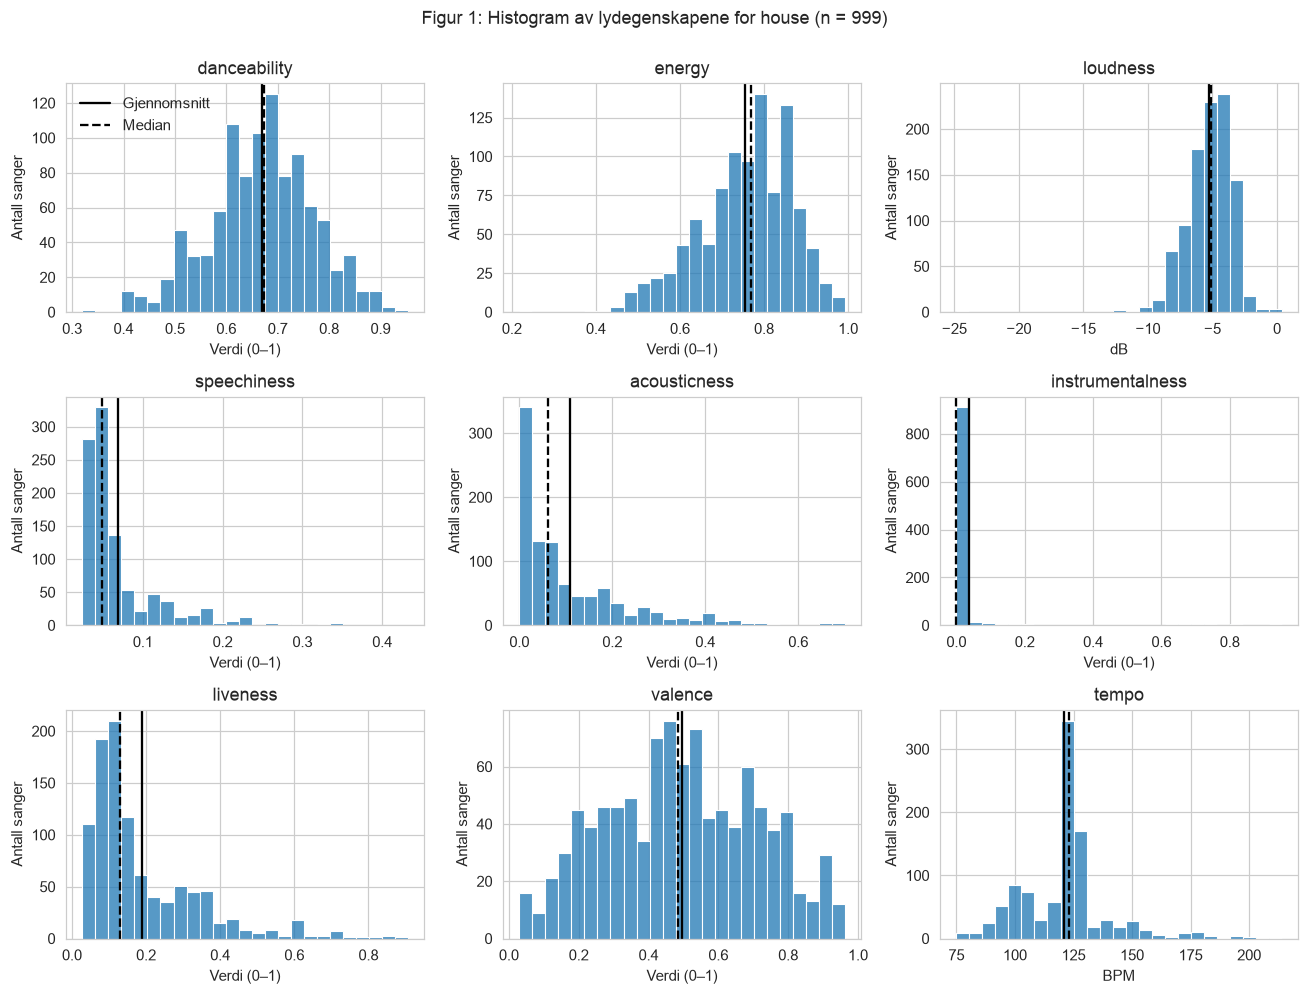

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, e in zip(axes.flat, egenskaper):
    sns.histplot(data[e], bins=25, edgecolor="white", ax=ax)
    ax.axvline(data[e].mean(),   color="black", lw=1.5, ls="-",  label="Gjennomsnitt")
    ax.axvline(data[e].median(), color="black", lw=1.5, ls="--", label="Median")
    ax.set_title(e)
    ax.set_xlabel("dB" if e == "loudness" else ("BPM" if e == "tempo" else "Verdi (0–1)"))
    ax.set_ylabel("Antall sanger")
axes.flat[0].legend(frameon=False)
fig.suptitle(f"Figur 1: Histogram av lydegenskapene for {SJANGER} (n = {len(data)})", y=1.0)
plt.tight_layout()
plt.savefig(f"figurer/fig1_histogram_{SJANGER}.png", bbox_inches="tight")
plt.show()

### Figur 2 – Spredning og uteliggere (boksplott)

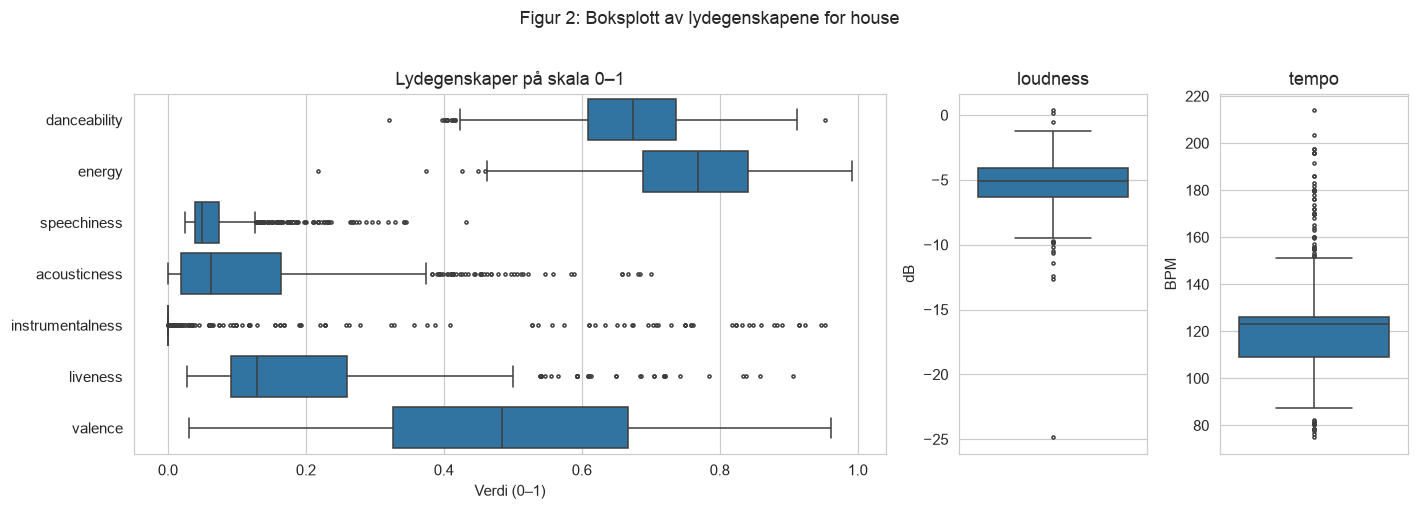

In [12]:
skala01 = ["danceability", "energy", "speechiness", "acousticness",
           "instrumentalness", "liveness", "valence"]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.5),
                                    gridspec_kw={"width_ratios": [4, 1, 1]})
sns.boxplot(data=data[skala01], orient="h", color="C0", fliersize=2, ax=ax1)
ax1.set_xlabel("Verdi (0–1)")
ax1.set_title("Lydegenskaper på skala 0–1")
sns.boxplot(y=data["loudness"], fliersize=2, ax=ax2)
ax2.set_ylabel("dB"); ax2.set_title("loudness")
sns.boxplot(y=data["tempo"], fliersize=2, ax=ax3)
ax3.set_ylabel("BPM"); ax3.set_title("tempo")
fig.suptitle(f"Figur 2: Boksplott av lydegenskapene for {SJANGER}", y=1.02)
plt.tight_layout()
plt.savefig(f"figurer/fig2_boksplott_{SJANGER}.png", bbox_inches="tight")
plt.show()

### Figur 3 – Sammenhenger mellom variablene (korrelasjonsmatrise)

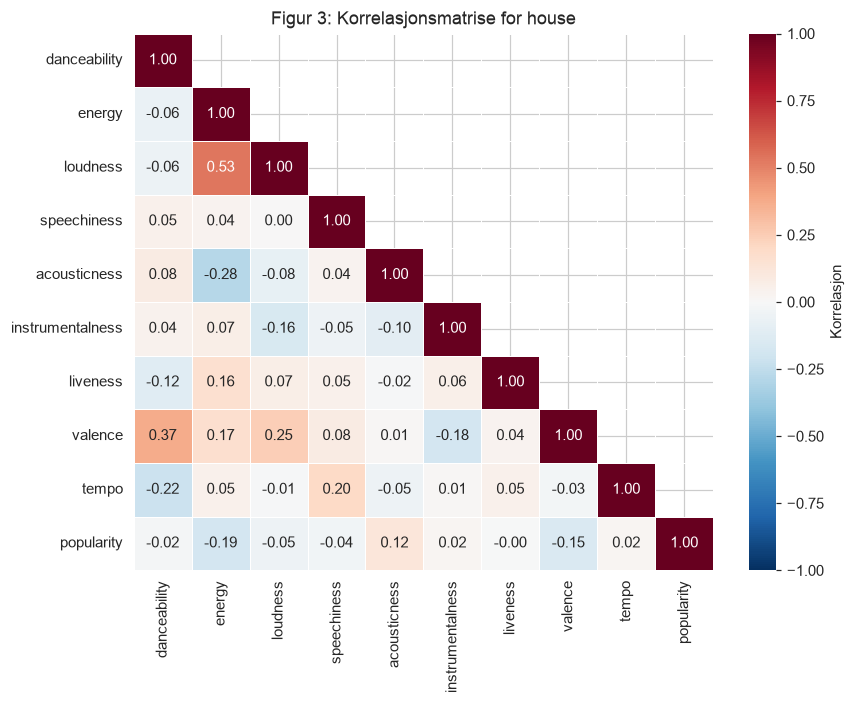

In [13]:
korr = data[egenskaper + ["popularity"]].corr()
maske = np.triu(np.ones_like(korr, dtype=bool), k=1)
plt.figure(figsize=(8, 6.5))
sns.heatmap(korr, mask=maske, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, linewidths=0.5, cbar_kws={"label": "Korrelasjon"})
plt.title(f"Figur 3: Korrelasjonsmatrise for {SJANGER}")
plt.tight_layout()
plt.savefig(f"figurer/fig3_korrelasjon_{SJANGER}.png", bbox_inches="tight")
plt.show()

### Figur 4 – Spredningsdiagram for de to sterkest korrelerte parene

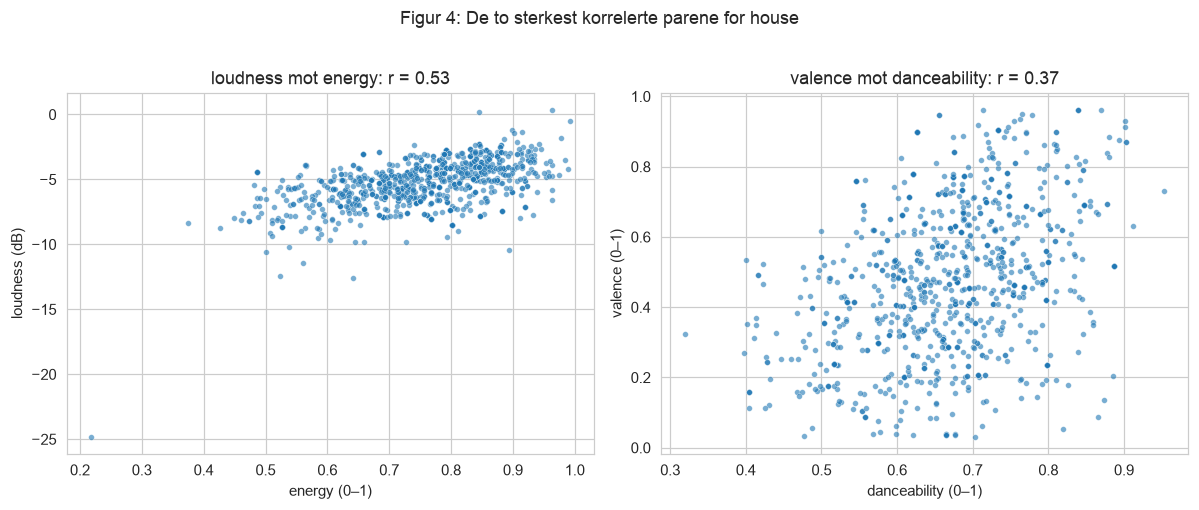

In [14]:
k_eg = data[egenskaper].corr()
par_k = k_eg.where(~np.triu(np.ones_like(k_eg, dtype=bool))).stack()
topp2 = par_k.reindex(par_k.abs().sort_values(ascending=False).index).head(2)
enhet = {"loudness": "dB", "tempo": "BPM"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ((y, x), r) in zip(axes, topp2.items()):
    sns.scatterplot(data=data, x=x, y=y, s=14, alpha=0.6, ax=ax)
    ax.set_xlabel(f"{x} ({enhet.get(x, '0–1')})")
    ax.set_ylabel(f"{y} ({enhet.get(y, '0–1')})")
    ax.set_title(f"{y} mot {x}: r = {r:.2f}")
fig.suptitle(f"Figur 4: De to sterkest korrelerte parene for {SJANGER}", y=1.02)
plt.tight_layout()
plt.savefig(f"figurer/fig4_scatter_{SJANGER}.png", bbox_inches="tight")
plt.show()